In [1]:
%pip install -q torch-geometric rdkit selfies scikit-learn seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:

from __future__ import annotations

import copy
import json
import math
import random
import time
from collections import Counter
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Any, Iterable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import selfies as sf
import torch
import torch.nn as nn
import torch.nn.functional as F
from rdkit import Chem, DataStructs
from rdkit.Chem import (
    Descriptors,
    Draw,
    QED,
    rdFingerprintGenerator,
    rdMolDescriptors,
)
from torch_geometric.data import Data
from torch_geometric.datasets import MoleculeNet
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, global_mean_pool
from torch_geometric.utils.smiles import from_smiles, x_map

## 1. Reproducible configuration

In [3]:
@dataclass(frozen=True)
class Config:
    random_seed: int = 42

    maximum_selfies_tokens: int = 100
    train_fraction: float = 0.80
    validation_fraction: float = 0.10

    model_dimension: int = 192
    feedforward_dimension: int = 512
    attention_heads: int = 6
    transformer_layers: int = 4
    gcn_layers: int = 3
    projection_dimension: int = 192
    dropout: float = 0.10

    batch_size: int = 256
    language_model_epochs: int = 15
    joint_epochs: int = 40
    minimum_joint_epochs: int = 15
    early_stopping_patience: int = 8
    early_stopping_minimum_delta: float = 1e-5

    language_model_learning_rate: float = 3e-4
    joint_transformer_learning_rate: float = 5e-5
    joint_alignment_learning_rate: float = 3e-4
    weight_decay: float = 1e-3
    gradient_clip_norm: float = 1.0

    contrastive_temperature: float = 0.07
    contrastive_loss_weight: float = 1.0
    positive_pair_loss_weight: float = 0.25

    generation_count_per_temperature: int = 300
    generation_temperatures: tuple[float, ...] = (0.8, 1.0, 1.2)
    generation_top_k: int = 20
    generation_top_p: float = 0.95
    minimum_tokens_before_eos: int = 5

    fingerprint_radius: int = 2
    fingerprint_size: int = 2048
    structural_novelty_threshold: float = 0.85


CONFIG = Config()

WORK_DIR = Path("/kaggle/working/molecule_alignment_project")
DATA_DIR = WORK_DIR / "data"
RESULT_DIR = WORK_DIR / "results_corrected"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ENABLED = DEVICE.type == "cuda"
NOTEBOOK_INITIALIZATION_TIME = time.time()


def set_random_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_random_seed(CONFIG.random_seed)


def json_safe(value: Any) -> Any:
    """Convert nested values to strict JSON-compatible Python objects."""
    if isinstance(value, dict):
        return {str(key): json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(item) for item in value]
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, torch.Tensor):
        if value.numel() == 1:
            return value.item()
        return value.detach().cpu().tolist()
    if isinstance(value, float) and not math.isfinite(value):
        return None
    return value


def save_json(payload: Any, path: Path) -> None:
    with path.open("w", encoding="utf-8") as file:
        json.dump(
            json_safe(payload),
            file,
            indent=2,
            ensure_ascii=False,
            allow_nan=False,
        )

## 2. Dataset preparation

In [4]:
SPECIAL_TOKENS = ["<pad>", "<bos>", "<eos>", "<unk>"]


def canonicalize_smiles(smiles: str) -> tuple[str, Chem.Mol]:
    molecule = Chem.MolFromSmiles(smiles, sanitize=True)
    if molecule is None:
        raise ValueError("RDKit parsing returned None.")

    Chem.SanitizeMol(molecule)
    canonical = Chem.MolToSmiles(
        molecule,
        canonical=True,
        isomericSmiles=True,
    )
    if not canonical:
        raise ValueError("Canonical SMILES is empty.")

    canonical_molecule = Chem.MolFromSmiles(canonical, sanitize=True)
    if canonical_molecule is None:
        raise ValueError("Canonical SMILES could not be reparsed.")
    return canonical, canonical_molecule


def prepare_unique_records(raw_dataset: MoleculeNet) -> tuple[list[dict], dict]:
    records: list[dict] = []
    seen_canonical_smiles: set[str] = set()

    invalid_structure_count = 0
    duplicate_count = 0
    selfies_conversion_failure_count = 0
    overlength_count = 0

    for original_index, sample in enumerate(raw_dataset):
        raw_smiles = str(sample.smiles)

        try:
            canonical_smiles, molecule = canonicalize_smiles(raw_smiles)
        except Exception:
            invalid_structure_count += 1
            continue

        if canonical_smiles in seen_canonical_smiles:
            duplicate_count += 1
            continue
        seen_canonical_smiles.add(canonical_smiles)

        try:
            selfies_string = sf.encoder(canonical_smiles)
            selfies_tokens = list(sf.split_selfies(selfies_string))
        except Exception:
            selfies_conversion_failure_count += 1
            continue

        if not selfies_tokens:
            selfies_conversion_failure_count += 1
            continue

        if len(selfies_tokens) > CONFIG.maximum_selfies_tokens:
            overlength_count += 1
            continue

        records.append(
            {
                "original_index": int(original_index),
                "raw_smiles": raw_smiles,
                "canonical_smiles": canonical_smiles,
                "selfies": selfies_string,
                "selfies_tokens": selfies_tokens,
                "target": float(sample.y.view(-1)[0].item()),
                "atom_count": int(molecule.GetNumAtoms()),
                "undirected_bond_count": int(molecule.GetNumBonds()),
            }
        )

    removed_count = (
        invalid_structure_count
        + duplicate_count
        + selfies_conversion_failure_count
        + overlength_count
    )

    statistics = {
        "original_molecule_count": int(len(raw_dataset)),
        "invalid_structure_count": invalid_structure_count,
        "duplicate_count": duplicate_count,
        "selfies_conversion_failure_count": selfies_conversion_failure_count,
        "overlength_selfies_count": overlength_count,
        "total_removed_count": removed_count,
        "usable_molecule_count": int(len(records)),
    }
    return records, statistics


def make_fixed_splits(number_of_records: int) -> dict[str, list[int]]:
    generator = torch.Generator().manual_seed(CONFIG.random_seed)
    permutation = torch.randperm(
        number_of_records,
        generator=generator,
    ).tolist()

    train_size = int(math.floor(CONFIG.train_fraction * number_of_records))
    validation_size = int(
        math.floor(CONFIG.validation_fraction * number_of_records)
    )

    return {
        "train": permutation[:train_size],
        "validation": permutation[
            train_size : train_size + validation_size
        ],
        "test": permutation[train_size + validation_size :],
    }


def build_vocabulary(
    records: list[dict],
    train_indices: Iterable[int],
) -> tuple[dict[str, int], list[str]]:
    training_tokens = {
        token
        for index in train_indices
        for token in records[index]["selfies_tokens"]
    }

    id_to_token = SPECIAL_TOKENS + sorted(training_tokens)
    token_to_id = {
        token: token_id
        for token_id, token in enumerate(id_to_token)
    }
    return token_to_id, id_to_token


def bond_weight_from_rdkit(bond: Chem.Bond) -> float:
    bond_type = bond.GetBondType()
    if bond_type == Chem.BondType.SINGLE:
        return 1.0
    if bond_type == Chem.BondType.DOUBLE:
        return 2.0
    if bond_type == Chem.BondType.TRIPLE:
        return 3.0
    if bond_type == Chem.BondType.AROMATIC:
        return 1.5
    return 1.0


def make_graph_data(
    record: dict,
    token_to_id: dict[str, int],
    maximum_complete_length: int,
    record_index: int,
    append_eos: bool = True,
) -> Data:
    molecule = Chem.MolFromSmiles(
        record["canonical_smiles"],
        sanitize=True,
    )
    if molecule is None:
        raise ValueError("A prepared canonical SMILES became invalid.")

    # from_smiles returns nine integer-coded categorical atom fields.
    graph = from_smiles(record["canonical_smiles"])
    graph.x = graph.x.to(torch.long)

    directed_edges: list[tuple[int, int]] = []
    directed_weights: list[float] = []

    for bond in molecule.GetBonds():
        source = int(bond.GetBeginAtomIdx())
        target = int(bond.GetEndAtomIdx())
        weight = bond_weight_from_rdkit(bond)

        directed_edges.extend([(source, target), (target, source)])
        directed_weights.extend([weight, weight])

    if directed_edges:
        graph.edge_index = torch.tensor(
            directed_edges,
            dtype=torch.long,
        ).t().contiguous()
        graph.edge_weight = torch.tensor(
            directed_weights,
            dtype=torch.float32,
        )
    else:
        graph.edge_index = torch.empty((2, 0), dtype=torch.long)
        graph.edge_weight = torch.empty((0,), dtype=torch.float32)

    pad_id = token_to_id["<pad>"]
    unk_id = token_to_id["<unk>"]

    complete_ids = [
        token_to_id["<bos>"],
        *[
            token_to_id.get(token, unk_id)
            for token in record["selfies_tokens"]
        ],
    ]
    if append_eos:
        complete_ids.append(token_to_id["<eos>"])

    if len(complete_ids) > maximum_complete_length:
        raise ValueError("Unexpected sequence longer than configured maximum.")

    complete_ids.extend(
        [pad_id] * (maximum_complete_length - len(complete_ids))
    )

    # Leading dimension makes PyG batch fixed-length sequences as [B, L].
    graph.sequence_ids = torch.tensor(
        complete_ids,
        dtype=torch.long,
    ).unsqueeze(0)
    graph.record_index = torch.tensor([record_index], dtype=torch.long)
    graph.y = torch.tensor([record["target"]], dtype=torch.float32)
    graph.canonical_smiles = record["canonical_smiles"]
    graph.selfies = record["selfies"]
    return graph


dataset_loading_start_time = time.time()
raw_dataset = MoleculeNet(
    root=str(DATA_DIR),
    name="Lipo",
)
dataset_loading_time_seconds = time.time() - dataset_loading_start_time

# The project permits initial download time to be reported separately.
# The complete experiment timer starts after the dataset is available.
experiment_start_time = time.time()

records, dataset_statistics = prepare_unique_records(raw_dataset)
split_indices = make_fixed_splits(len(records))

token_to_id, id_to_token = build_vocabulary(
    records,
    split_indices["train"],
)

PAD_ID = token_to_id["<pad>"]
BOS_ID = token_to_id["<bos>"]
EOS_ID = token_to_id["<eos>"]
UNK_ID = token_to_id["<unk>"]
VOCABULARY_SIZE = len(id_to_token)
MAX_COMPLETE_SEQUENCE_LENGTH = CONFIG.maximum_selfies_tokens + 2

all_graphs = [
    make_graph_data(
        record=record,
        token_to_id=token_to_id,
        maximum_complete_length=MAX_COMPLETE_SEQUENCE_LENGTH,
        record_index=index,
    )
    for index, record in enumerate(records)
]

split_graphs = {
    split_name: [all_graphs[index] for index in indices]
    for split_name, indices in split_indices.items()
}

train_graph_dataset = split_graphs["train"]
validation_graph_dataset = split_graphs["validation"]
test_graph_dataset = split_graphs["test"]

sequence_lengths = np.asarray(
    [len(record["selfies_tokens"]) for record in records],
    dtype=np.int64,
)

dataset_statistics.update(
    {
        "split_sizes": {
            name: len(indices)
            for name, indices in split_indices.items()
        },
        "vocabulary_size": VOCABULARY_SIZE,
        "average_atom_count": float(
            np.mean([record["atom_count"] for record in records])
        ),
        "average_undirected_bond_count": float(
            np.mean(
                [record["undirected_bond_count"] for record in records]
            )
        ),
        "selfies_length_minimum": int(sequence_lengths.min()),
        "selfies_length_average": float(sequence_lengths.mean()),
        "selfies_length_maximum": int(sequence_lengths.max()),
        "unknown_token_counts": {
            split_name: int(
                sum(
                    token not in token_to_id
                    for index in split_indices[split_name]
                    for token in records[index]["selfies_tokens"]
                )
            )
            for split_name in ("validation", "test")
        },
    }
)

save_json(dataset_statistics, RESULT_DIR / "dataset_statistics.json")
save_json(token_to_id, RESULT_DIR / "selfies_vocabulary.json")
save_json(split_indices, RESULT_DIR / "fixed_split_indices.json")

plt.figure(figsize=(8, 5))
plt.hist(sequence_lengths, bins=30, color="#315A8C", edgecolor="white")
plt.xlabel("SELFIES token count")
plt.ylabel("Molecule count")
plt.title("SELFIES sequence-length distribution")
plt.tight_layout()
plt.savefig(
    RESULT_DIR / "selfies_sequence_length_distribution.png",
    dpi=220,
)
plt.close()


# x_map is the categorical schema used by torch_geometric.utils.from_smiles.
ATOM_FEATURE_CARDINALITIES = [len(values) for values in x_map.values()]

assert len(ATOM_FEATURE_CARDINALITIES) == all_graphs[0].x.shape[1]
assert CONFIG.model_dimension % CONFIG.attention_heads == 0
assert CONFIG.transformer_layers == 4
assert CONFIG.attention_heads == 6
assert CONFIG.model_dimension == 192
assert CONFIG.feedforward_dimension == 512
assert CONFIG.gcn_layers == 3

print(json.dumps(dataset_statistics, indent=2))
print("Atom-feature cardinalities:", ATOM_FEATURE_CARDINALITIES)

{
  "original_molecule_count": 4200,
  "invalid_structure_count": 0,
  "duplicate_count": 0,
  "selfies_conversion_failure_count": 0,
  "overlength_selfies_count": 6,
  "total_removed_count": 6,
  "usable_molecule_count": 4194,
  "split_sizes": {
    "train": 3355,
    "validation": 419,
    "test": 420
  },
  "vocabulary_size": 52,
  "average_atom_count": 26.96638054363376,
  "average_undirected_bond_count": 29.4241773962804,
  "selfies_length_minimum": 9,
  "selfies_length_average": 44.388888888888886,
  "selfies_length_maximum": 94,
  "unknown_token_counts": {
    "validation": 0,
    "test": 2
  }
}
Atom-feature cardinalities: [119, 9, 11, 12, 9, 5, 8, 2, 2]


## 3. DataLoaders

In [5]:
pin_memory = AMP_ENABLED

training_generator = torch.Generator().manual_seed(CONFIG.random_seed)

train_loader = DataLoader(
    train_graph_dataset,
    batch_size=CONFIG.batch_size,
    shuffle=True,
    drop_last=True,
    generator=training_generator,
    num_workers=0,
    pin_memory=pin_memory,
)

train_evaluation_loader = DataLoader(
    train_graph_dataset,
    batch_size=CONFIG.batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=pin_memory,
)

validation_loader = DataLoader(
    validation_graph_dataset,
    batch_size=CONFIG.batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=pin_memory,
)

test_loader = DataLoader(
    test_graph_dataset,
    batch_size=CONFIG.batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=pin_memory,
)

## 4. Correct independent GCN and Transformer encoders

In [6]:
class CategoricalAtomEncoder(nn.Module):
    """Embed each categorical atom field separately and add embeddings."""

    def __init__(
        self,
        cardinalities: list[int],
        embedding_dimension: int,
    ) -> None:
        super().__init__()
        self.embedding_tables = nn.ModuleList(
            [
                nn.Embedding(cardinality, embedding_dimension)
                for cardinality in cardinalities
            ]
        )

        for embedding in self.embedding_tables:
            nn.init.xavier_uniform_(embedding.weight)

    def forward(self, atom_features: torch.Tensor) -> torch.Tensor:
        if atom_features.ndim != 2:
            raise ValueError("atom_features must have shape [N, fields].")
        if atom_features.shape[1] != len(self.embedding_tables):
            raise ValueError("Unexpected number of categorical atom fields.")

        encoded = 0.0
        for field_index, embedding in enumerate(self.embedding_tables):
            encoded = encoded + embedding(atom_features[:, field_index])
        return encoded


class ResidualGCNBlock(nn.Module):
    def __init__(self, dimension: int, dropout: float) -> None:
        super().__init__()
        self.convolution = GCNConv(
            in_channels=dimension,
            out_channels=dimension,
            add_self_loops=True,
            normalize=True,
        )
        self.normalization = nn.LayerNorm(dimension)
        self.dropout = nn.Dropout(dropout)

    def forward(
        self,
        node_embeddings: torch.Tensor,
        edge_index: torch.Tensor,
        edge_weight: torch.Tensor,
    ) -> torch.Tensor:
        residual = node_embeddings
        updated = self.convolution(
            node_embeddings,
            edge_index,
            edge_weight=edge_weight,
        )
        updated = F.gelu(updated)
        updated = self.normalization(updated)
        updated = self.dropout(updated)
        return residual + updated


class MolecularGCNEncoder(nn.Module):
    def __init__(self, config: Config) -> None:
        super().__init__()
        self.atom_encoder = CategoricalAtomEncoder(
            cardinalities=ATOM_FEATURE_CARDINALITIES,
            embedding_dimension=config.model_dimension,
        )
        self.layers = nn.ModuleList(
            [
                ResidualGCNBlock(
                    dimension=config.model_dimension,
                    dropout=config.dropout,
                )
                for _ in range(config.gcn_layers)
            ]
        )
        self.final_normalization = nn.LayerNorm(config.model_dimension)

    def forward(self, graph_batch: Data) -> torch.Tensor:
        node_embeddings = self.atom_encoder(graph_batch.x)

        for layer in self.layers:
            node_embeddings = layer(
                node_embeddings=node_embeddings,
                edge_index=graph_batch.edge_index,
                edge_weight=graph_batch.edge_weight,
            )

        node_embeddings = self.final_normalization(node_embeddings)
        graph_embeddings = global_mean_pool(
            node_embeddings,
            graph_batch.batch,
        )
        return graph_embeddings


class CausalSelfiesTransformer(nn.Module):
    def __init__(self, config: Config, vocabulary_size: int) -> None:
        super().__init__()
        self.model_dimension = config.model_dimension
        self.token_embedding = nn.Embedding(
            vocabulary_size,
            config.model_dimension,
            padding_idx=PAD_ID,
        )
        self.position_embedding = nn.Embedding(
            MAX_COMPLETE_SEQUENCE_LENGTH,
            config.model_dimension,
        )
        self.embedding_dropout = nn.Dropout(config.dropout)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=config.model_dimension,
            nhead=config.attention_heads,
            dim_feedforward=config.feedforward_dimension,
            dropout=config.dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer=encoder_layer,
            num_layers=config.transformer_layers,
            norm=nn.LayerNorm(config.model_dimension),
            enable_nested_tensor=False,
        )
        self.language_model_head = nn.Linear(
            config.model_dimension,
            vocabulary_size,
            bias=False,
        )

        # Weight tying improves parameter efficiency for a small LM.
        self.language_model_head.weight = self.token_embedding.weight
        self.reset_parameters()

    def reset_parameters(self) -> None:
        """Use stable small embeddings before applying sqrt(d_model)."""
        nn.init.normal_(self.token_embedding.weight, mean=0.0, std=0.02)
        nn.init.normal_(self.position_embedding.weight, mean=0.0, std=0.02)
        if self.token_embedding.padding_idx is not None:
            with torch.no_grad():
                self.token_embedding.weight[
                    self.token_embedding.padding_idx
                ].zero_()

    @staticmethod
    def causal_mask(length: int, device: torch.device) -> torch.Tensor:
        return torch.triu(
            torch.ones(
                (length, length),
                dtype=torch.bool,
                device=device,
            ),
            diagonal=1,
        )

    def hidden_states(
        self,
        sequence_ids: torch.Tensor,
    ) -> torch.Tensor:
        batch_size, sequence_length = sequence_ids.shape
        if sequence_length > MAX_COMPLETE_SEQUENCE_LENGTH:
            raise ValueError("Sequence exceeds learned positional embeddings.")

        positions = torch.arange(
            sequence_length,
            device=sequence_ids.device,
        ).unsqueeze(0).expand(batch_size, -1)

        embeddings = (
            self.token_embedding(sequence_ids)
            * math.sqrt(self.model_dimension)
            + self.position_embedding(positions)
        )
        embeddings = self.embedding_dropout(embeddings)

        return self.encoder(
            embeddings,
            mask=self.causal_mask(sequence_length, sequence_ids.device),
            src_key_padding_mask=sequence_ids.eq(PAD_ID),
        )

    def forward(
        self,
        complete_sequence_ids: torch.Tensor,
    ) -> dict[str, torch.Tensor]:
        hidden = self.hidden_states(complete_sequence_ids)

        # Hidden state at position t predicts the token at position t+1.
        token_logits = self.language_model_head(hidden[:, :-1, :])
        token_labels = complete_sequence_ids[:, 1:]

        eos_mask = complete_sequence_ids.eq(EOS_ID)
        has_eos = eos_mask.any(dim=1)
        eos_positions = eos_mask.to(torch.int64).argmax(dim=1)
        last_nonpadding_positions = (
            complete_sequence_ids.ne(PAD_ID).sum(dim=1) - 1
        ).clamp_min(0)
        representation_positions = torch.where(
            has_eos,
            eos_positions,
            last_nonpadding_positions,
        )
        batch_indices = torch.arange(
            complete_sequence_ids.shape[0],
            device=complete_sequence_ids.device,
        )
        sequence_embeddings = hidden[
            batch_indices,
            representation_positions,
        ]

        return {
            "token_logits": token_logits,
            "token_labels": token_labels,
            "sequence_embeddings": sequence_embeddings,
            "representation_positions": representation_positions,
            "has_eos": has_eos,
            "hidden_states": hidden,
        }

    def next_token_logits(
        self,
        generated_ids: torch.Tensor,
    ) -> tuple[torch.Tensor, torch.Tensor]:
        hidden = self.hidden_states(generated_ids)
        final_state = hidden[:, -1, :]
        logits = self.language_model_head(final_state)
        return logits, final_state


class ProjectionNetwork(nn.Module):
    def __init__(
        self,
        input_dimension: int,
        output_dimension: int,
        dropout: float,
    ) -> None:
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dimension, input_dimension),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(input_dimension, output_dimension),
        )

    def forward(self, embeddings: torch.Tensor) -> torch.Tensor:
        return F.normalize(self.network(embeddings), p=2, dim=-1)


class MolecularAlignmentModel(nn.Module):
    def __init__(self, config: Config, vocabulary_size: int) -> None:
        super().__init__()
        self.graph_encoder = MolecularGCNEncoder(config)
        self.sequence_encoder = CausalSelfiesTransformer(
            config=config,
            vocabulary_size=vocabulary_size,
        )
        self.graph_projection = ProjectionNetwork(
            input_dimension=config.model_dimension,
            output_dimension=config.projection_dimension,
            dropout=config.dropout,
        )
        self.sequence_projection = ProjectionNetwork(
            input_dimension=config.model_dimension,
            output_dimension=config.projection_dimension,
            dropout=config.dropout,
        )

    def forward(self, graph_batch: Data) -> dict[str, torch.Tensor]:
        graph_embedding = self.graph_encoder(graph_batch)
        sequence_output = self.sequence_encoder(graph_batch.sequence_ids)

        graph_projection = self.graph_projection(graph_embedding)
        sequence_projection = self.sequence_projection(
            sequence_output["sequence_embeddings"]
        )

        return {
            **sequence_output,
            "graph_embeddings": graph_embedding,
            "graph_projections": graph_projection,
            "sequence_projections": sequence_projection,
        }


def language_model_loss(
    token_logits: torch.Tensor,
    token_labels: torch.Tensor,
) -> torch.Tensor:
    return F.cross_entropy(
        token_logits.reshape(-1, token_logits.shape[-1]),
        token_labels.reshape(-1),
        ignore_index=PAD_ID,
    )


def symmetric_contrastive_loss(
    graph_projections: torch.Tensor,
    sequence_projections: torch.Tensor,
) -> torch.Tensor:
    logits = (
        graph_projections @ sequence_projections.T
    ) / CONFIG.contrastive_temperature

    labels = torch.arange(logits.shape[0], device=logits.device)
    graph_to_sequence = F.cross_entropy(logits, labels)
    sequence_to_graph = F.cross_entropy(logits.T, labels)
    return 0.5 * (graph_to_sequence + sequence_to_graph)


def positive_pair_cosine_loss(
    graph_projections: torch.Tensor,
    sequence_projections: torch.Tensor,
) -> torch.Tensor:
    matching_cosines = (
        graph_projections * sequence_projections
    ).sum(dim=-1)
    return (1.0 - matching_cosines).mean()


model = MolecularAlignmentModel(
    config=CONFIG,
    vocabulary_size=VOCABULARY_SIZE,
).to(DEVICE)

## 5. Architectural smoke test

In [7]:
smoke_batch = next(iter(train_loader)).to(DEVICE)

model.train()
smoke_output = model(smoke_batch)
smoke_token_loss = language_model_loss(
    smoke_output["token_logits"],
    smoke_output["token_labels"],
)
smoke_contrastive_loss = symmetric_contrastive_loss(
    smoke_output["graph_projections"],
    smoke_output["sequence_projections"],
)
smoke_pair_loss = positive_pair_cosine_loss(
    smoke_output["graph_projections"],
    smoke_output["sequence_projections"],
)
smoke_total_loss = (
    smoke_token_loss
    + CONFIG.contrastive_loss_weight * smoke_contrastive_loss
    + CONFIG.positive_pair_loss_weight * smoke_pair_loss
)
smoke_total_loss.backward()

assert smoke_output["graph_embeddings"].shape == (
    smoke_batch.num_graphs,
    CONFIG.model_dimension,
)
assert smoke_output["sequence_embeddings"].shape == (
    smoke_batch.num_graphs,
    CONFIG.model_dimension,
)
assert smoke_output["graph_projections"].shape == (
    smoke_batch.num_graphs,
    CONFIG.projection_dimension,
)
assert smoke_output["sequence_projections"].shape == (
    smoke_batch.num_graphs,
    CONFIG.projection_dimension,
)
assert smoke_output["token_logits"].shape[:2] == (
    smoke_batch.num_graphs,
    MAX_COMPLETE_SEQUENCE_LENGTH - 1,
)
assert torch.allclose(
    smoke_output["graph_projections"].norm(dim=-1),
    torch.ones(smoke_batch.num_graphs, device=DEVICE),
    atol=1e-5,
)
assert torch.allclose(
    smoke_output["sequence_projections"].norm(dim=-1),
    torch.ones(smoke_batch.num_graphs, device=DEVICE),
    atol=1e-5,
)

for parameter_name, parameter in model.named_parameters():
    if parameter.grad is not None:
        assert torch.isfinite(parameter.grad).all(), parameter_name

model.zero_grad(set_to_none=True)

architecture_summary = {
    "total_parameters": sum(p.numel() for p in model.parameters()),
    "trainable_parameters": sum(
        p.numel() for p in model.parameters() if p.requires_grad
    ),
    "transformer_layers": len(model.sequence_encoder.encoder.layers),
    "attention_heads": CONFIG.attention_heads,
    "model_dimension": CONFIG.model_dimension,
    "feedforward_dimension": CONFIG.feedforward_dimension,
    "gcn_layers": len(model.graph_encoder.layers),
    "atom_embedding_tables": len(
        model.graph_encoder.atom_encoder.embedding_tables
    ),
    "smoke_token_loss": float(smoke_token_loss.item()),
    "smoke_contrastive_loss": float(smoke_contrastive_loss.item()),
    "smoke_pair_loss": float(smoke_pair_loss.item()),
    "smoke_total_loss": float(smoke_total_loss.item()),
}
save_json(architecture_summary, RESULT_DIR / "architecture_summary.json")
print("Corrected architecture smoke test passed.")
print(json.dumps(architecture_summary, indent=2))

Corrected architecture smoke test passed.
{
  "total_parameters": 1710080,
  "trainable_parameters": 1710080,
  "transformer_layers": 4,
  "attention_heads": 6,
  "model_dimension": 192,
  "feedforward_dimension": 512,
  "gcn_layers": 3,
  "atom_embedding_tables": 9,
  "smoke_token_loss": 3.947286605834961,
  "smoke_contrastive_loss": 5.642096042633057,
  "smoke_pair_loss": 1.0369583368301392,
  "smoke_total_loss": 9.848621368408203
}


## 6. Shared epoch utilities

In [8]:
def new_grad_scaler() -> torch.amp.GradScaler:
    return torch.amp.GradScaler(
        device=DEVICE.type,
        enabled=AMP_ENABLED,
    )


def autocast_context():
    return torch.autocast(
        device_type=DEVICE.type,
        dtype=torch.float16,
        enabled=AMP_ENABLED,
    )


def token_statistics(
    logits: torch.Tensor,
    labels: torch.Tensor,
) -> tuple[int, int]:
    mask = labels.ne(PAD_ID)
    predictions = logits.argmax(dim=-1)
    correct = int((predictions.eq(labels) & mask).sum().item())
    valid = int(mask.sum().item())
    return correct, valid


def run_language_model_epoch(
    alignment_model: MolecularAlignmentModel,
    data_loader: DataLoader,
    optimizer: torch.optim.Optimizer | None,
    scaler: torch.amp.GradScaler | None,
) -> dict[str, float]:
    training = optimizer is not None
    alignment_model.sequence_encoder.train(training)

    loss_sum = 0.0
    correct_token_count = 0
    valid_token_count = 0

    for graph_batch in data_loader:
        graph_batch = graph_batch.to(
            DEVICE,
            non_blocking=pin_memory,
        )

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with autocast_context():
                output = alignment_model.sequence_encoder(
                    graph_batch.sequence_ids
                )
                loss = language_model_loss(
                    output["token_logits"],
                    output["token_labels"],
                )

            if training:
                assert scaler is not None
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(
                    alignment_model.sequence_encoder.parameters(),
                    CONFIG.gradient_clip_norm,
                )
                scaler.step(optimizer)
                scaler.update()

        correct, valid = token_statistics(
            output["token_logits"],
            output["token_labels"],
        )
        loss_sum += float(loss.item()) * valid
        correct_token_count += correct
        valid_token_count += valid

    mean_loss = loss_sum / valid_token_count
    return {
        "token_loss": mean_loss,
        "token_accuracy": correct_token_count / valid_token_count,
        "perplexity": math.exp(min(mean_loss, 50.0)),
    }


def run_joint_epoch(
    alignment_model: MolecularAlignmentModel,
    data_loader: DataLoader,
    optimizer: torch.optim.Optimizer | None,
    scaler: torch.amp.GradScaler | None,
) -> dict[str, float]:
    training = optimizer is not None
    alignment_model.train(training)

    token_loss_sum = 0.0
    contrastive_loss_sum = 0.0
    pair_loss_sum = 0.0
    graph_count = 0
    valid_token_count = 0
    correct_token_count = 0

    for graph_batch in data_loader:
        graph_batch = graph_batch.to(
            DEVICE,
            non_blocking=pin_memory,
        )
        current_graph_count = int(graph_batch.num_graphs)

        if current_graph_count < 2:
            continue

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with autocast_context():
                output = alignment_model(graph_batch)
                token_loss = language_model_loss(
                    output["token_logits"],
                    output["token_labels"],
                )
                contrastive_loss = symmetric_contrastive_loss(
                    output["graph_projections"],
                    output["sequence_projections"],
                )
                pair_loss = positive_pair_cosine_loss(
                    output["graph_projections"],
                    output["sequence_projections"],
                )
                total_loss = (
                    token_loss
                    + CONFIG.contrastive_loss_weight * contrastive_loss
                    + CONFIG.positive_pair_loss_weight * pair_loss
                )

            if training:
                assert scaler is not None
                scaler.scale(total_loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(
                    alignment_model.parameters(),
                    CONFIG.gradient_clip_norm,
                )
                scaler.step(optimizer)
                scaler.update()

        correct, valid = token_statistics(
            output["token_logits"],
            output["token_labels"],
        )

        token_loss_sum += float(token_loss.item()) * valid
        contrastive_loss_sum += (
            float(contrastive_loss.item()) * current_graph_count
        )
        pair_loss_sum += float(pair_loss.item()) * current_graph_count
        graph_count += current_graph_count
        valid_token_count += valid
        correct_token_count += correct

    mean_token_loss = token_loss_sum / valid_token_count
    mean_contrastive_loss = contrastive_loss_sum / graph_count
    mean_pair_loss = pair_loss_sum / graph_count
    mean_total_loss = (
        mean_token_loss
        + CONFIG.contrastive_loss_weight * mean_contrastive_loss
        + CONFIG.positive_pair_loss_weight * mean_pair_loss
    )

    return {
        "total_loss": mean_total_loss,
        "token_loss": mean_token_loss,
        "contrastive_loss": mean_contrastive_loss,
        "positive_pair_loss": mean_pair_loss,
        "token_accuracy": correct_token_count / valid_token_count,
        "perplexity": math.exp(min(mean_token_loss, 50.0)),
    }


@torch.no_grad()
def collect_alignment_projections(
    alignment_model: MolecularAlignmentModel,
    data_loader: DataLoader,
) -> dict[str, Any]:
    alignment_model.eval()
    graph_projections: list[torch.Tensor] = []
    sequence_projections: list[torch.Tensor] = []
    record_indices: list[int] = []
    canonical_smiles: list[str] = []

    for graph_batch in data_loader:
        graph_batch = graph_batch.to(
            DEVICE,
            non_blocking=pin_memory,
        )
        output = alignment_model(graph_batch)
        graph_projections.append(
            output["graph_projections"].float().cpu()
        )
        sequence_projections.append(
            output["sequence_projections"].float().cpu()
        )
        record_indices.extend(
            graph_batch.record_index.view(-1).cpu().tolist()
        )
        canonical_smiles.extend(list(graph_batch.canonical_smiles))

    return {
        "graph": torch.cat(graph_projections, dim=0),
        "sequence": torch.cat(sequence_projections, dim=0),
        "record_indices": record_indices,
        "canonical_smiles": canonical_smiles,
    }


def top_k_retrieval_accuracy(
    similarities: torch.Tensor,
    k: int,
) -> float:
    true_indices = torch.arange(similarities.shape[0])
    retrieved = similarities.topk(
        k=min(k, similarities.shape[1]),
        dim=1,
    ).indices
    return float(
        retrieved.eq(true_indices.unsqueeze(1)).any(dim=1).float().mean()
    )


@torch.no_grad()
def alignment_retrieval_diagnostics(
    alignment_model: MolecularAlignmentModel,
    data_loader: DataLoader,
) -> dict[str, float]:
    embeddings = collect_alignment_projections(
        alignment_model,
        data_loader,
    )
    similarities = embeddings["graph"] @ embeddings["sequence"].T
    count = similarities.shape[0]
    matching_mask = torch.eye(count, dtype=torch.bool)
    matching = similarities[matching_mask]
    nonmatching = similarities[~matching_mask]

    graph_to_sequence_top1 = top_k_retrieval_accuracy(similarities, 1)
    graph_to_sequence_top5 = top_k_retrieval_accuracy(similarities, 5)
    sequence_to_graph_top1 = top_k_retrieval_accuracy(
        similarities.T,
        1,
    )
    sequence_to_graph_top5 = top_k_retrieval_accuracy(
        similarities.T,
        5,
    )
    matching_mean = float(matching.mean().item())
    nonmatching_mean = float(nonmatching.mean().item())
    cosine_gap = matching_mean - nonmatching_mean
    average_top5 = 0.5 * (
        graph_to_sequence_top5 + sequence_to_graph_top5
    )

    # Retrieval is the primary goal. The cosine gap breaks near-ties.
    selection_score = average_top5 + 0.10 * max(cosine_gap, 0.0)

    return {
        "graph_to_sequence_top1": graph_to_sequence_top1,
        "graph_to_sequence_top5": graph_to_sequence_top5,
        "sequence_to_graph_top1": sequence_to_graph_top1,
        "sequence_to_graph_top5": sequence_to_graph_top5,
        "average_matching_pair_cosine": matching_mean,
        "average_nonmatching_pair_cosine": nonmatching_mean,
        "matching_nonmatching_cosine_gap": cosine_gap,
        "average_bidirectional_top5": average_top5,
        "selection_score": selection_score,
    }

## 7. Fifteen-epoch language-model warm-up

In [9]:
set_random_seed(CONFIG.random_seed)

warmup_start_time = time.time()

warmup_optimizer = torch.optim.AdamW(
    model.sequence_encoder.parameters(),
    lr=CONFIG.language_model_learning_rate,
    weight_decay=CONFIG.weight_decay,
)
warmup_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    warmup_optimizer,
    T_max=CONFIG.language_model_epochs,
    eta_min=CONFIG.language_model_learning_rate * 0.05,
)
warmup_scaler = new_grad_scaler()

warmup_history: list[dict[str, float]] = []
best_warmup_validation_loss = float("inf")
best_warmup_state: dict[str, torch.Tensor] | None = None

for epoch in range(1, CONFIG.language_model_epochs + 1):
    train_metrics = run_language_model_epoch(
        model,
        train_loader,
        warmup_optimizer,
        warmup_scaler,
    )
    validation_metrics = run_language_model_epoch(
        model,
        validation_loader,
        optimizer=None,
        scaler=None,
    )

    warmup_history.append(
        {
            "epoch": epoch,
            "learning_rate": warmup_optimizer.param_groups[0]["lr"],
            **{f"train_{k}": v for k, v in train_metrics.items()},
            **{
                f"validation_{k}": v
                for k, v in validation_metrics.items()
            },
        }
    )

    if validation_metrics["token_loss"] < best_warmup_validation_loss:
        best_warmup_validation_loss = validation_metrics["token_loss"]
        best_warmup_state = copy.deepcopy(
            model.sequence_encoder.state_dict()
        )

    print(
        f"Warm-up {epoch:02d}/{CONFIG.language_model_epochs} | "
        f"train token loss {train_metrics['token_loss']:.4f} | "
        f"val token loss {validation_metrics['token_loss']:.4f} | "
        f"val acc {validation_metrics['token_accuracy']:.4f} | "
        f"val ppl {validation_metrics['perplexity']:.3f}"
    )
    warmup_scheduler.step()

assert best_warmup_state is not None
model.sequence_encoder.load_state_dict(best_warmup_state)
warmup_time_seconds = time.time() - warmup_start_time

warmup_history_df = pd.DataFrame(warmup_history)
warmup_history_df.to_csv(
    RESULT_DIR / "language_model_warmup_history.csv",
    index=False,
)
torch.save(
    {
        "sequence_encoder_state_dict": best_warmup_state,
        "validation_token_loss": best_warmup_validation_loss,
        "config": asdict(CONFIG),
        "token_to_id": token_to_id,
    },
    RESULT_DIR / "best_language_model_warmup.pt",
)

Warm-up 01/15 | train token loss 2.9707 | val token loss 2.5546 | val acc 0.3543 | val ppl 12.866
Warm-up 02/15 | train token loss 2.4017 | val token loss 2.2357 | val acc 0.4018 | val ppl 9.353
Warm-up 03/15 | train token loss 2.1477 | val token loss 2.0651 | val acc 0.4245 | val ppl 7.886
Warm-up 04/15 | train token loss 2.0192 | val token loss 1.9613 | val acc 0.4371 | val ppl 7.109
Warm-up 05/15 | train token loss 1.9383 | val token loss 1.8871 | val acc 0.4536 | val ppl 6.600
Warm-up 06/15 | train token loss 1.8764 | val token loss 1.8230 | val acc 0.4704 | val ppl 6.190
Warm-up 07/15 | train token loss 1.8301 | val token loss 1.7791 | val acc 0.4771 | val ppl 5.925
Warm-up 08/15 | train token loss 1.7935 | val token loss 1.7411 | val acc 0.4847 | val ppl 5.703
Warm-up 09/15 | train token loss 1.7621 | val token loss 1.7091 | val acc 0.4903 | val ppl 5.524
Warm-up 10/15 | train token loss 1.7392 | val token loss 1.6869 | val acc 0.4977 | val ppl 5.403
Warm-up 11/15 | train token l

## 8. Joint training for up to forty additional epochs

In [10]:
joint_optimizer = torch.optim.AdamW(
    [
        {
            "params": model.sequence_encoder.parameters(),
            "lr": CONFIG.joint_transformer_learning_rate,
            "name": "transformer",
        },
        {
            "params": [
                *model.graph_encoder.parameters(),
                *model.graph_projection.parameters(),
                *model.sequence_projection.parameters(),
            ],
            "lr": CONFIG.joint_alignment_learning_rate,
            "name": "alignment",
        },
    ],
    weight_decay=CONFIG.weight_decay,
)
joint_scheduler = torch.optim.lr_scheduler.LambdaLR(
    joint_optimizer,
    lr_lambda=lambda completed_epoch: (
        0.05
        + 0.95
        * 0.5
        * (
            1.0
            + math.cos(
                math.pi
                * min(completed_epoch, CONFIG.joint_epochs)
                / CONFIG.joint_epochs
            )
        )
    ),
)
joint_scaler = new_grad_scaler()

joint_history: list[dict[str, float]] = []
best_joint_validation_loss = float("inf")
best_joint_alignment_score = -float("inf")
best_joint_validation_retrieval: dict[str, float] | None = None
best_joint_epoch = 0
epochs_without_improvement = 0
joint_stopping_reason = "maximum_epochs"
best_checkpoint_path = RESULT_DIR / "best_joint_alignment_model.pt"

training_start_time = time.time()

for epoch in range(1, CONFIG.joint_epochs + 1):
    epoch_start = time.time()
    train_metrics = run_joint_epoch(
        model,
        train_loader,
        joint_optimizer,
        joint_scaler,
    )
    validation_metrics = run_joint_epoch(
        model,
        validation_loader,
        optimizer=None,
        scaler=None,
    )
    validation_retrieval = alignment_retrieval_diagnostics(
        model,
        validation_loader,
    )

    record = {
        "epoch": epoch,
        "transformer_learning_rate": (
            joint_optimizer.param_groups[0]["lr"]
        ),
        "alignment_learning_rate": (
            joint_optimizer.param_groups[1]["lr"]
        ),
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{
            f"validation_{k}": v
            for k, v in validation_metrics.items()
        },
        **{
            f"validation_retrieval_{k}": v
            for k, v in validation_retrieval.items()
        },
        "duration_seconds": time.time() - epoch_start,
    }
    joint_history.append(record)

    improved = (
        validation_retrieval["selection_score"]
        > best_joint_alignment_score
        + CONFIG.early_stopping_minimum_delta
    )

    if improved:
        best_joint_validation_loss = validation_metrics["total_loss"]
        best_joint_alignment_score = validation_retrieval[
            "selection_score"
        ]
        best_joint_validation_retrieval = dict(validation_retrieval)
        best_joint_epoch = epoch
        epochs_without_improvement = 0
        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "validation_metrics": validation_metrics,
                "validation_retrieval": validation_retrieval,
                "selection_score": best_joint_alignment_score,
                "config": asdict(CONFIG),
                "token_to_id": token_to_id,
                "id_to_token": id_to_token,
                "atom_feature_cardinalities": (
                    ATOM_FEATURE_CARDINALITIES
                ),
                "maximum_complete_sequence_length": (
                    MAX_COMPLETE_SEQUENCE_LENGTH
                ),
            },
            best_checkpoint_path,
        )
    else:
        epochs_without_improvement += 1

    print(
        f"Joint {epoch:02d}/{CONFIG.joint_epochs} | "
        f"train total {train_metrics['total_loss']:.4f} | "
        f"val total {validation_metrics['total_loss']:.4f} | "
        f"val token {validation_metrics['token_loss']:.4f} | "
        f"val contrastive "
        f"{validation_metrics['contrastive_loss']:.4f} | "
        f"val pair {validation_metrics['positive_pair_loss']:.4f} | "
        f"val bi-top5 "
        f"{validation_retrieval['average_bidirectional_top5']:.4f} | "
        f"cos gap "
        f"{validation_retrieval['matching_nonmatching_cosine_gap']:.4f}"
    )

    joint_scheduler.step()

    if (
        epoch < CONFIG.joint_epochs
        and epoch >= CONFIG.minimum_joint_epochs
        and epochs_without_improvement
        >= CONFIG.early_stopping_patience
    ):
        joint_stopping_reason = "early_stopping"
        print(f"Early stopping activated at joint epoch {epoch}.")
        break

training_time_seconds = time.time() - training_start_time

assert best_checkpoint_path.exists()
assert best_joint_validation_retrieval is not None
best_checkpoint = torch.load(
    best_checkpoint_path,
    map_location=DEVICE,
    weights_only=False,
)
model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()

joint_history_df = pd.DataFrame(joint_history)
joint_history_df.to_csv(
    RESULT_DIR / "joint_training_history.csv",
    index=False,
)

Joint 01/40 | train total 7.2981 | val total 6.7578 | val token 1.6403 | val contrastive 5.0729 | val pair 0.1784 | val bi-top5 0.0453 | cos gap 0.0327
Joint 02/40 | train total 6.7344 | val total 6.3125 | val token 1.6525 | val contrastive 4.5980 | val pair 0.2477 | val bi-top5 0.1134 | cos gap 0.1993
Joint 03/40 | train total 6.3366 | val total 6.0782 | val token 1.6484 | val contrastive 4.3746 | val pair 0.2209 | val bi-top5 0.1480 | cos gap 0.2153
Joint 04/40 | train total 6.0056 | val total 5.8241 | val token 1.6497 | val contrastive 4.1027 | val pair 0.2869 | val bi-top5 0.1981 | cos gap 0.2608
Joint 05/40 | train total 5.6384 | val total 5.6750 | val token 1.6511 | val contrastive 3.9488 | val pair 0.3008 | val bi-top5 0.2422 | cos gap 0.3010
Joint 06/40 | train total 5.1890 | val total 5.6356 | val token 1.6519 | val contrastive 3.9042 | val pair 0.3179 | val bi-top5 0.2375 | cos gap 0.3836
Joint 07/40 | train total 4.7146 | val total 5.3526 | val token 1.6537 | val contrastive

## 9. Required training plots

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(
    warmup_history_df["epoch"],
    warmup_history_df["train_token_loss"],
    label="Train",
)
axes[0].plot(
    warmup_history_df["epoch"],
    warmup_history_df["validation_token_loss"],
    label="Validation",
)
axes[0].set_title("Language-model warm-up")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Token cross-entropy")
axes[0].legend()

axes[1].plot(
    joint_history_df["epoch"],
    joint_history_df["train_total_loss"],
    label="Train",
)
axes[1].plot(
    joint_history_df["epoch"],
    joint_history_df["validation_total_loss"],
    label="Validation",
)
axes[1].set_title("Joint alignment training")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Combined loss")
axes[1].legend()
fig.tight_layout()
fig.savefig(RESULT_DIR / "warmup_and_joint_losses.png", dpi=220)
plt.close(fig)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for column, label, axis in [
    ("validation_token_loss", "Token loss", axes[0, 0]),
    ("validation_contrastive_loss", "Contrastive loss", axes[0, 1]),
    ("validation_positive_pair_loss", "Positive-pair loss", axes[1, 0]),
    ("validation_token_accuracy", "Token accuracy", axes[1, 1]),
]:
    axis.plot(joint_history_df["epoch"], joint_history_df[column])
    axis.set_title(label)
    axis.set_xlabel("Joint epoch")
    axis.set_ylabel(label)
fig.tight_layout()
fig.savefig(RESULT_DIR / "joint_component_metrics.png", dpi=220)
plt.close(fig)

fig, axis = plt.subplots(figsize=(7, 4.8))
axis.plot(
    joint_history_df["epoch"],
    joint_history_df["train_perplexity"],
    label="Train",
)
axis.plot(
    joint_history_df["epoch"],
    joint_history_df["validation_perplexity"],
    label="Validation",
)
axis.set_title("Token perplexity during joint training")
axis.set_xlabel("Joint epoch")
axis.set_ylabel("Perplexity")
axis.legend()
fig.tight_layout()
fig.savefig(RESULT_DIR / "joint_perplexity.png", dpi=220)
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].plot(
    joint_history_df["epoch"],
    joint_history_df[
        "validation_retrieval_graph_to_sequence_top5"
    ],
    label="Graph to sequence",
)
axes[0].plot(
    joint_history_df["epoch"],
    joint_history_df[
        "validation_retrieval_sequence_to_graph_top5"
    ],
    label="Sequence to graph",
)
axes[0].set_title("Validation retrieval Top-5")
axes[0].set_xlabel("Joint epoch")
axes[0].set_ylabel("Top-5 accuracy")
axes[0].legend()

axes[1].plot(
    joint_history_df["epoch"],
    joint_history_df[
        "validation_retrieval_matching_nonmatching_cosine_gap"
    ],
    color="#A43F3F",
)
axes[1].axhline(0.0, color="black", linewidth=0.8, linestyle="--")
axes[1].set_title("Matching vs nonmatching cosine gap")
axes[1].set_xlabel("Joint epoch")
axes[1].set_ylabel("Cosine gap")
fig.tight_layout()
fig.savefig(
    RESULT_DIR / "validation_alignment_diagnostics.png",
    dpi=220,
)
plt.close(fig)

## 10. Bidirectional retrieval

In [12]:
@torch.no_grad()
def collect_projections(
    alignment_model: MolecularAlignmentModel,
    data_loader: DataLoader,
) -> dict[str, Any]:
    return collect_alignment_projections(
        alignment_model,
        data_loader,
    )


test_embeddings = collect_projections(model, test_loader)
test_similarity_matrix = (
    test_embeddings["graph"] @ test_embeddings["sequence"].T
)

matching_mask = torch.eye(
    test_similarity_matrix.shape[0],
    dtype=torch.bool,
)

matching_similarity = test_similarity_matrix[matching_mask]
nonmatching_similarity = test_similarity_matrix[~matching_mask]
test_count = test_similarity_matrix.shape[0]

retrieval_metrics = {
    "test_molecule_count": int(test_count),
    "graph_to_sequence_top1": top_k_retrieval_accuracy(
        test_similarity_matrix,
        1,
    ),
    "graph_to_sequence_top5": top_k_retrieval_accuracy(
        test_similarity_matrix,
        5,
    ),
    "sequence_to_graph_top1": top_k_retrieval_accuracy(
        test_similarity_matrix.T,
        1,
    ),
    "sequence_to_graph_top5": top_k_retrieval_accuracy(
        test_similarity_matrix.T,
        5,
    ),
    "average_matching_pair_cosine": float(
        matching_similarity.mean().item()
    ),
    "average_nonmatching_pair_cosine": float(
        nonmatching_similarity.mean().item()
    ),
    "random_chance_top1": 1.0 / test_count,
    "random_chance_top5": min(5.0 / test_count, 1.0),
}
save_json(retrieval_metrics, RESULT_DIR / "test_retrieval_metrics.json")
print("Test retrieval metrics:")
print(json.dumps(retrieval_metrics, indent=2))

Test retrieval metrics:
{
  "test_molecule_count": 420,
  "graph_to_sequence_top1": 0.5047619342803955,
  "graph_to_sequence_top5": 0.8595238327980042,
  "sequence_to_graph_top1": 0.488095223903656,
  "sequence_to_graph_top5": 0.8357142806053162,
  "average_matching_pair_cosine": 0.8806191682815552,
  "average_nonmatching_pair_cosine": 0.0306259673088789,
  "random_chance_top1": 0.002380952380952381,
  "random_chance_top5": 0.011904761904761904
}


## 11. Unconditional top-k plus nucleus SELFIES generation

In [13]:
def top_k_top_p_sample(
    logits: torch.Tensor,
    top_k: int,
    top_p: float,
) -> int:
    top_k = min(top_k, logits.numel())
    top_values, top_indices = torch.topk(logits, k=top_k)

    probabilities = torch.softmax(top_values, dim=-1)
    sorted_probabilities, sort_order = torch.sort(
        probabilities,
        descending=True,
    )
    cumulative = torch.cumsum(sorted_probabilities, dim=-1)

    remove = cumulative > top_p
    remove[1:] = remove[:-1].clone()
    remove[0] = False

    sorted_probabilities[remove] = 0.0
    sorted_probabilities = (
        sorted_probabilities / sorted_probabilities.sum()
    )

    sampled_sorted_index = torch.multinomial(
        sorted_probabilities,
        num_samples=1,
    )
    selected_top_index = sort_order[sampled_sorted_index]
    return int(top_indices[selected_top_index].item())


@torch.no_grad()
def generate_one_selfies(
    sequence_model: CausalSelfiesTransformer,
    temperature: float,
) -> dict[str, Any]:
    sequence_model.eval()
    generated_ids = [BOS_ID]

    for generation_step in range(CONFIG.maximum_selfies_tokens):
        input_ids = torch.tensor(
            generated_ids,
            dtype=torch.long,
            device=DEVICE,
        ).unsqueeze(0)

        logits, _ = sequence_model.next_token_logits(input_ids)
        logits = logits[0].float() / temperature

        logits[PAD_ID] = -torch.inf
        logits[BOS_ID] = -torch.inf
        logits[UNK_ID] = -torch.inf

        if generation_step < CONFIG.minimum_tokens_before_eos:
            logits[EOS_ID] = -torch.inf

        next_id = top_k_top_p_sample(
            logits,
            top_k=CONFIG.generation_top_k,
            top_p=CONFIG.generation_top_p,
        )
        generated_ids.append(next_id)

        if next_id == EOS_ID:
            break

    content_ids = [
        token_id
        for token_id in generated_ids[1:]
        if token_id not in (EOS_ID, PAD_ID)
    ]
    tokens = [id_to_token[token_id] for token_id in content_ids]

    return {
        "temperature": float(temperature),
        "generated_ids": generated_ids,
        "tokens": tokens,
        "selfies": "".join(tokens),
        "generated_token_count": len(tokens),
        "terminated_with_eos": generated_ids[-1] == EOS_ID,
    }


generated_samples = []

for temperature in CONFIG.generation_temperatures:
    for sample_index in range(CONFIG.generation_count_per_temperature):
        sample = generate_one_selfies(
            model.sequence_encoder,
            temperature=temperature,
        )
        sample["sample_index"] = sample_index
        generated_samples.append(sample)

save_json(
    generated_samples,
    RESULT_DIR / "all_generated_selfies.json",
)

## 12. Complete staged generated-molecule validation

In [14]:
def molecule_properties(molecule: Chem.Mol) -> dict[str, Any]:
    atoms = list(molecule.GetAtoms())
    return {
        "heavy_atom_count": int(molecule.GetNumHeavyAtoms()),
        "molecular_weight": float(Descriptors.MolWt(molecule)),
        "absolute_molecular_formal_charge": abs(
            int(Chem.GetFormalCharge(molecule))
        ),
        "molecular_formula": rdMolDescriptors.CalcMolFormula(molecule),
        "element_atomic_numbers": {
            int(atom.GetAtomicNum()) for atom in atoms
        },
        "has_dummy_atom": any(atom.GetAtomicNum() == 0 for atom in atoms),
        "has_radical_electron": any(
            atom.GetNumRadicalElectrons() != 0 for atom in atoms
        ),
    }


training_molecules = [
    Chem.MolFromSmiles(records[index]["canonical_smiles"])
    for index in split_indices["train"]
]
assert all(molecule is not None for molecule in training_molecules)

training_properties = [
    molecule_properties(molecule)
    for molecule in training_molecules
    if molecule is not None
]

training_elements = set().union(
    *[
        properties["element_atomic_numbers"]
        for properties in training_properties
    ]
)
training_heavy_atoms = np.asarray(
    [properties["heavy_atom_count"] for properties in training_properties],
    dtype=float,
)
training_molecular_weights = np.asarray(
    [properties["molecular_weight"] for properties in training_properties],
    dtype=float,
)

validation_thresholds = {
    "training_elements": sorted(training_elements),
    "heavy_atom_percentile_1": float(
        np.percentile(training_heavy_atoms, 1)
    ),
    "heavy_atom_percentile_99": float(
        np.percentile(training_heavy_atoms, 99)
    ),
    "molecular_weight_percentile_1": float(
        np.percentile(training_molecular_weights, 1)
    ),
    "molecular_weight_percentile_99": float(
        np.percentile(training_molecular_weights, 99)
    ),
    "maximum_absolute_molecular_formal_charge": int(
        max(
            properties["absolute_molecular_formal_charge"]
            for properties in training_properties
        )
    ),
}
save_json(
    validation_thresholds,
    RESULT_DIR / "generation_validation_thresholds.json",
)

fingerprint_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=CONFIG.fingerprint_radius,
    fpSize=CONFIG.fingerprint_size,
)
training_fingerprints = [
    fingerprint_generator.GetFingerprint(molecule)
    for molecule in training_molecules
    if molecule is not None
]
training_canonical_set = {
    records[index]["canonical_smiles"]
    for index in split_indices["train"]
}

REJECTION_STAGES = (
    "selfies_decoding_exception",
    "empty_decoded_smiles",
    "rdkit_parse_failure",
    "rdkit_sanitization_failure",
    "multiple_connected_components",
    "dummy_atom",
    "element_absent_from_training",
    "nonzero_radical_electrons",
    "heavy_atom_count_outside_percentiles",
    "molecular_weight_outside_percentiles",
    "formal_charge_exceeds_training_maximum",
    "empty_canonical_smiles",
)


def reject(result: dict, reason: str) -> dict:
    result["accepted"] = False
    result["rejection_reason"] = reason
    return result


def validate_generated_sample(sample: dict[str, Any]) -> dict[str, Any]:
    result = {
        "temperature": sample["temperature"],
        "sample_index": sample["sample_index"],
        "selfies": sample["selfies"],
        "generated_token_count": sample["generated_token_count"],
        "terminated_with_eos": sample["terminated_with_eos"],
        "rdkit_valid": False,
        "accepted": False,
        "rejection_reason": None,
        "decoded_smiles": None,
        "canonical_smiles": None,
        "heavy_atom_count": None,
        "molecular_weight": None,
        "molecular_formula": None,
        "absolute_molecular_formal_charge": None,
        "qed": None,
        "is_exact_novel": None,
        "maximum_training_fingerprint_similarity": None,
        "is_structurally_novel": None,
    }

    try:
        decoded_smiles = sf.decoder(sample["selfies"])
    except Exception:
        return reject(result, "selfies_decoding_exception")

    if not decoded_smiles:
        return reject(result, "empty_decoded_smiles")
    result["decoded_smiles"] = decoded_smiles

    molecule = Chem.MolFromSmiles(decoded_smiles, sanitize=False)
    if molecule is None:
        return reject(result, "rdkit_parse_failure")

    try:
        Chem.SanitizeMol(molecule)
    except Exception:
        return reject(result, "rdkit_sanitization_failure")

    result["rdkit_valid"] = True

    if len(Chem.GetMolFrags(molecule)) != 1:
        return reject(result, "multiple_connected_components")

    properties = molecule_properties(molecule)

    if properties["has_dummy_atom"]:
        return reject(result, "dummy_atom")

    if not properties["element_atomic_numbers"].issubset(training_elements):
        return reject(result, "element_absent_from_training")

    if properties["has_radical_electron"]:
        return reject(result, "nonzero_radical_electrons")

    if not (
        validation_thresholds["heavy_atom_percentile_1"]
        <= properties["heavy_atom_count"]
        <= validation_thresholds["heavy_atom_percentile_99"]
    ):
        return reject(result, "heavy_atom_count_outside_percentiles")

    if not (
        validation_thresholds["molecular_weight_percentile_1"]
        <= properties["molecular_weight"]
        <= validation_thresholds["molecular_weight_percentile_99"]
    ):
        return reject(result, "molecular_weight_outside_percentiles")

    if (
        properties["absolute_molecular_formal_charge"]
        > validation_thresholds[
            "maximum_absolute_molecular_formal_charge"
        ]
    ):
        return reject(result, "formal_charge_exceeds_training_maximum")

    canonical_smiles = Chem.MolToSmiles(
        molecule,
        canonical=True,
        isomericSmiles=True,
    )
    if not canonical_smiles:
        return reject(result, "empty_canonical_smiles")

    fingerprint = fingerprint_generator.GetFingerprint(molecule)
    similarities = DataStructs.BulkTanimotoSimilarity(
        fingerprint,
        training_fingerprints,
    )
    maximum_similarity = float(max(similarities))
    is_exact_novel = canonical_smiles not in training_canonical_set
    is_structurally_novel = (
        is_exact_novel
        and maximum_similarity < CONFIG.structural_novelty_threshold
    )

    result.update(
        {
            "accepted": True,
            "canonical_smiles": canonical_smiles,
            "heavy_atom_count": properties["heavy_atom_count"],
            "molecular_weight": properties["molecular_weight"],
            "molecular_formula": properties["molecular_formula"],
            "absolute_molecular_formal_charge": properties[
                "absolute_molecular_formal_charge"
            ],
            "qed": float(QED.qed(molecule)),
            "is_exact_novel": bool(is_exact_novel),
            "maximum_training_fingerprint_similarity": (
                maximum_similarity
            ),
            "is_structurally_novel": bool(is_structurally_novel),
        }
    )
    return result


validation_results = [
    validate_generated_sample(sample)
    for sample in generated_samples
]
validation_results_df = pd.DataFrame(validation_results)
validation_results_df.to_csv(
    RESULT_DIR / "generated_molecule_validation_results.csv",
    index=False,
)

validation_results_df[
    validation_results_df["accepted"]
].groupby(
    "temperature",
    group_keys=False,
).head(10).to_csv(
    RESULT_DIR / "accepted_generation_examples.csv",
    index=False,
)
validation_results_df[
    ~validation_results_df["accepted"]
].groupby(
    ["temperature", "rejection_reason"],
    dropna=False,
    group_keys=False,
).head(2).to_csv(
    RESULT_DIR / "rejected_generation_examples.csv",
    index=False,
)


def summarize_temperature(
    temperature_frame: pd.DataFrame,
) -> dict[str, Any]:
    total = len(temperature_frame)
    rdkit_valid_count = int(temperature_frame["rdkit_valid"].sum())
    accepted_frame = temperature_frame[temperature_frame["accepted"]]
    accepted_count = len(accepted_frame)

    unique_accepted = accepted_frame.drop_duplicates(
        subset=["canonical_smiles"]
    )
    unique_count = len(unique_accepted)
    exact_novel_count = int(unique_accepted["is_exact_novel"].sum())
    structural_novel_count = int(
        unique_accepted["is_structurally_novel"].sum()
    )
    observed_rejection_counts = (
        temperature_frame.loc[
            ~temperature_frame["accepted"],
            "rejection_reason",
        ]
        .value_counts(dropna=False)
        .to_dict()
    )

    return {
        "generated_count": total,
        "rdkit_valid_count": rdkit_valid_count,
        "rdkit_validity": rdkit_valid_count / total,
        "accepted_count": accepted_count,
        "acceptance_rate": accepted_count / total,
        "terminated_with_eos_count": int(
            temperature_frame["terminated_with_eos"].sum()
        ),
        "terminated_with_eos_rate": float(
            temperature_frame["terminated_with_eos"].mean()
        ),
        "generated_token_count_minimum": int(
            temperature_frame["generated_token_count"].min()
        ),
        "generated_token_count_average": float(
            temperature_frame["generated_token_count"].mean()
        ),
        "generated_token_count_maximum": int(
            temperature_frame["generated_token_count"].max()
        ),
        "unique_accepted_count": unique_count,
        "uniqueness": (
            unique_count / accepted_count if accepted_count else 0.0
        ),
        "exact_novel_unique_count": exact_novel_count,
        "exact_novelty": (
            exact_novel_count / unique_count if unique_count else 0.0
        ),
        "structurally_novel_unique_count": structural_novel_count,
        "structural_novelty": (
            structural_novel_count / unique_count if unique_count else 0.0
        ),
        "mean_qed_of_accepted": (
            float(accepted_frame["qed"].mean())
            if accepted_count
            else None
        ),
        "mean_maximum_training_fingerprint_similarity": (
            float(
                unique_accepted[
                    "maximum_training_fingerprint_similarity"
                ].mean()
            )
            if unique_count
            else None
        ),
        "rejection_counts": {
            reason: int(observed_rejection_counts.get(reason, 0))
            for reason in REJECTION_STAGES
        },
    }


generation_metrics = {
    str(temperature): summarize_temperature(
        validation_results_df[
            np.isclose(
                validation_results_df["temperature"],
                temperature,
            )
        ]
    )
    for temperature in CONFIG.generation_temperatures
}
save_json(
    generation_metrics,
    RESULT_DIR / "generation_metrics_by_temperature.json",
)

rejection_count_rows = []
for temperature in CONFIG.generation_temperatures:
    temperature_metrics = generation_metrics[str(temperature)]
    for stage in REJECTION_STAGES:
        rejection_count_rows.append(
            {
                "temperature": temperature,
                "validation_stage": stage,
                "rejection_count": temperature_metrics[
                    "rejection_counts"
                ][stage],
            }
        )
pd.DataFrame(rejection_count_rows).to_csv(
    RESULT_DIR / "rejection_counts_all_stages.csv",
    index=False,
)

print("Generation metrics:")
print(json.dumps(generation_metrics, indent=2))

Generation metrics:
{
  "0.8": {
    "generated_count": 300,
    "rdkit_valid_count": 300,
    "rdkit_validity": 1.0,
    "accepted_count": 263,
    "acceptance_rate": 0.8766666666666667,
    "terminated_with_eos_count": 300,
    "terminated_with_eos_rate": 1.0,
    "generated_token_count_minimum": 12,
    "generated_token_count_average": 46.46333333333333,
    "generated_token_count_maximum": 99,
    "unique_accepted_count": 263,
    "uniqueness": 1.0,
    "exact_novel_unique_count": 263,
    "exact_novelty": 1.0,
    "structurally_novel_unique_count": 263,
    "structural_novelty": 1.0,
    "mean_qed_of_accepted": 0.512865425735697,
    "mean_maximum_training_fingerprint_similarity": 0.18162040766525442,
    "rejection_counts": {
      "selfies_decoding_exception": 0,
      "empty_decoded_smiles": 0,
      "rdkit_parse_failure": 0,
      "rdkit_sanitization_failure": 0,
      "multiple_connected_components": 0,
      "dummy_atom": 0,
      "element_absent_from_training": 0,
      "no

## 13. Generated examples and nearest neighbors

In [15]:
def graph_from_generated_row(row: pd.Series) -> Data:
    if bool(row["terminated_with_eos"]):
        representation_selfies = sf.encoder(row["canonical_smiles"])
    else:
        # Preserve the exact unfinished generation so the representation
        # comes from its final generated token, not an artificial <eos>.
        representation_selfies = row["selfies"]

    tokens = list(sf.split_selfies(representation_selfies))
    if len(tokens) > CONFIG.maximum_selfies_tokens:
        representation_selfies = row["selfies"]
        tokens = list(sf.split_selfies(representation_selfies))

    temporary_record = {
        "canonical_smiles": row["canonical_smiles"],
        "selfies": representation_selfies,
        "selfies_tokens": tokens,
        "target": 0.0,
    }
    graph = make_graph_data(
        record=temporary_record,
        token_to_id=token_to_id,
        maximum_complete_length=MAX_COMPLETE_SEQUENCE_LENGTH,
        record_index=-1,
        append_eos=bool(row["terminated_with_eos"]),
    )
    graph.representation_selfies = representation_selfies
    return graph


accepted_mask = (
    validation_results_df["accepted"]
    .astype("boolean")
    .fillna(False)
)
exact_novel_mask = (
    validation_results_df["is_exact_novel"]
    .astype("boolean")
    .fillna(False)
)

accepted_novel_frame = (
    validation_results_df[accepted_mask & exact_novel_mask]
    .drop_duplicates(subset=["canonical_smiles"])
    .reset_index(drop=True)
)

training_embeddings = collect_projections(
    model,
    train_evaluation_loader,
)
training_combined = F.normalize(
    training_embeddings["graph"]
    + training_embeddings["sequence"],
    p=2,
    dim=-1,
)

nearest_neighbor_rows: list[dict[str, Any]] = []

if len(accepted_novel_frame) > 0:
    generated_graphs = [
        graph_from_generated_row(row)
        for _, row in accepted_novel_frame.iterrows()
    ]
    generated_loader = DataLoader(
        generated_graphs,
        batch_size=CONFIG.batch_size,
        shuffle=False,
    )
    generated_embeddings = collect_projections(model, generated_loader)
    generated_combined = F.normalize(
        generated_embeddings["graph"]
        + generated_embeddings["sequence"],
        p=2,
        dim=-1,
    )

    generated_graph_sequence_similarity = (
        generated_embeddings["graph"]
        * generated_embeddings["sequence"]
    ).sum(dim=-1)
    nearest_similarity_matrix = generated_combined @ training_combined.T
    nearest_similarities, nearest_indices = nearest_similarity_matrix.max(
        dim=1
    )

    for generated_index, row in accepted_novel_frame.iterrows():
        nearest_index = int(nearest_indices[generated_index].item())
        nearest_neighbor_rows.append(
            {
                "temperature": float(row["temperature"]),
                "generated_selfies": row["selfies"],
                "generated_canonical_smiles": row["canonical_smiles"],
                "molecular_formula": row["molecular_formula"],
                "terminated_with_eos": bool(row["terminated_with_eos"]),
                "graph_sequence_cosine_similarity": float(
                    generated_graph_sequence_similarity[
                        generated_index
                    ].item()
                ),
                "nearest_training_smiles": training_embeddings[
                    "canonical_smiles"
                ][nearest_index],
                "nearest_embedding_similarity": float(
                    nearest_similarities[generated_index].item()
                ),
                "maximum_fingerprint_similarity": float(
                    row["maximum_training_fingerprint_similarity"]
                ),
                "is_structurally_novel": bool(
                    row["is_structurally_novel"]
                ),
            }
        )

nearest_neighbor_df = pd.DataFrame(nearest_neighbor_rows)
nearest_neighbor_df.to_csv(
    RESULT_DIR / "accepted_novel_nearest_neighbors.csv",
    index=False,
)

if len(nearest_neighbor_df) < 10:
    raise RuntimeError(
        f"Only {len(nearest_neighbor_df)} nearest-neighbor examples are "
        "available; the project requires at least 10."
    )

## 14. Required RDKit molecule grid

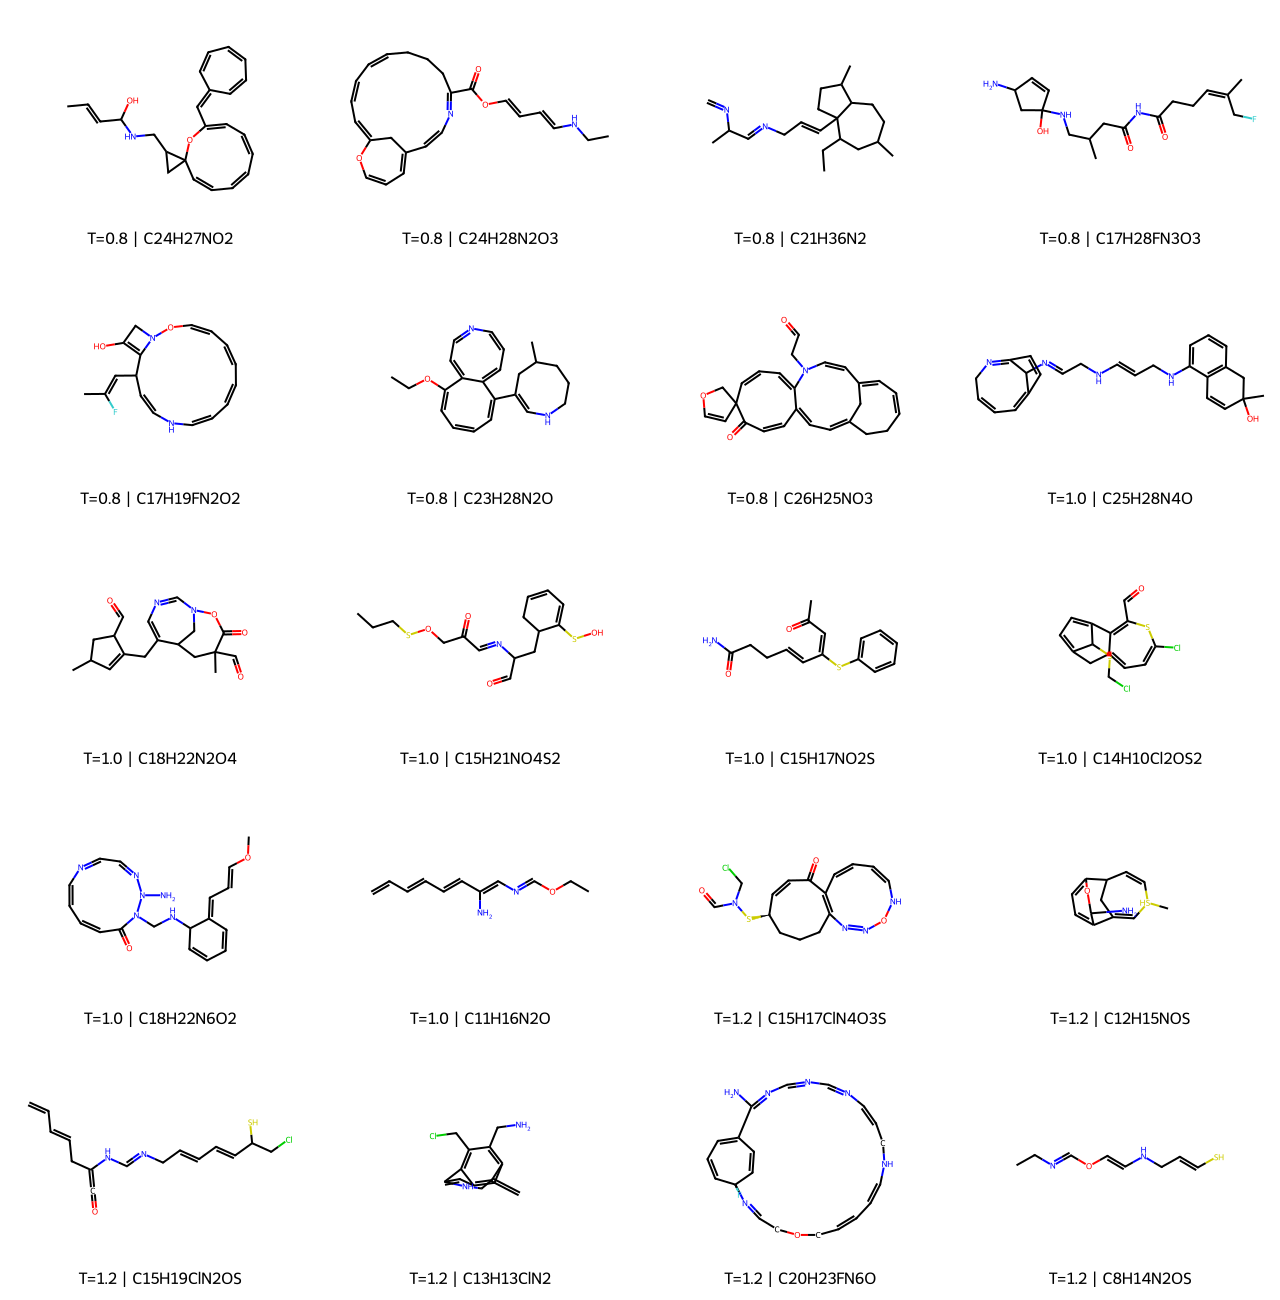

,temperature,molecular_formula,canonical_smiles
0,0.8,C24H27NO2,CC=CC(O)NCC1CC12C=CC=CC=CC=C(C=C1C=CC=CC=C1)O2
1,0.8,C24H28N2O3,CCNC=CC=COC(=O)C1=NC=CC2=CC=COC(=CC=CC=CCCC1)C2
2,0.8,C21H36N2,C=NC(C)C=NCC=CC12CCC(C)C1CCC(C)CC2CC
3,0.8,C17H28FN3O3,CC(=CCCC(=O)NC(=O)CC(C)CNC1(O)C=CC(N)C1)CF
4,0.8,C17H19FN2O2,CC(F)=CC1C=CNC=CC=CC=CC=CON2CC(O)=C12
5,0.8,C23H28N2O,CCOc1ccccc(C2=CNCCCC(C)C2)c2cccnccc1-2
6,0.8,C26H25NO3,O=CCN1C=CC2=CC=CCCC(=CC=C3C=CC(=O)C4(C=CC=C31)...
7,1.0,C25H28N4O,CC1(O)C=Cc2c(cccc2NCC=CNCC=NC2C3=CC=CCN=C2C=C3)C1
8,1.0,C18H22N2O4,CC1C=C(CC2=CN=CN3CC2CC(C)(C=O)C(=O)O3)C(C=O)C1
9,1.0,C15H21NO4S2,CCCSOCC(=O)C=NC(C=O)CC1CC=CC=C1SO


In [16]:
def select_balanced_temperature_rows(
    frame: pd.DataFrame,
    total_count: int,
) -> pd.DataFrame:
    selected_indices: list[int] = []
    temperatures = list(CONFIG.generation_temperatures)
    base_quota, remainder = divmod(total_count, len(temperatures))

    for position, temperature in enumerate(temperatures):
        quota = base_quota + int(position < remainder)
        candidates = frame[
            np.isclose(frame["temperature"], temperature)
        ]
        selected_indices.extend(candidates.head(quota).index.tolist())

    if len(selected_indices) < total_count:
        remaining = frame.loc[
            ~frame.index.isin(selected_indices)
        ].head(total_count - len(selected_indices))
        selected_indices.extend(remaining.index.tolist())

    return frame.loc[selected_indices].head(total_count).reset_index(drop=True)


grid_rows = select_balanced_temperature_rows(
    accepted_novel_frame,
    total_count=20,
)
grid_molecules = [
    Chem.MolFromSmiles(smiles)
    for smiles in grid_rows["canonical_smiles"].tolist()
]
assert all(molecule is not None for molecule in grid_molecules)

grid_legends = [
    f"T={row.temperature:.1f} | {row.molecular_formula}"
    for row in grid_rows.itertuples(index=False)
]

grid_path = RESULT_DIR / "accepted_novel_molecule_grid.png"
grid_rows[
    [
        "temperature",
        "canonical_smiles",
        "molecular_formula",
        "qed",
        "maximum_training_fingerprint_similarity",
    ]
].to_csv(
    RESULT_DIR / "molecule_grid_manifest.csv",
    index=False,
)

if len(grid_molecules) < 20:
    raise RuntimeError(
        f"Only {len(grid_molecules)} accepted novel molecules are "
        "available; at least 20 are required for the final grid."
    )

grid_output = Draw.MolsToGridImage(
    grid_molecules,
    molsPerRow=4,
    subImgSize=(320, 260),
    legends=grid_legends,
    useSVG=False,
    returnPNG=True,
)

if hasattr(grid_output, "data"):
    png_data = grid_output.data
elif isinstance(grid_output, (bytes, bytearray)):
    png_data = grid_output
else:
    from io import BytesIO

    buffer = BytesIO()
    grid_output.save(buffer, format="PNG")
    png_data = buffer.getvalue()

grid_path.write_bytes(bytes(png_data))

try:
    from IPython.display import Image as IPythonImage
    from IPython.display import display

    display(IPythonImage(filename=str(grid_path)))
    display(
        grid_rows[
            [
                "temperature",
                "molecular_formula",
                "canonical_smiles",
            ]
        ]
    )
except ImportError:
    print(f"Molecule grid saved to: {grid_path}")

## 15. Strict final summary and checks

In [17]:
final_validation_metrics = run_joint_epoch(
    model,
    validation_loader,
    optimizer=None,
    scaler=None,
)
final_test_metrics = run_joint_epoch(
    model,
    test_loader,
    optimizer=None,
    scaler=None,
)
experiment_time_seconds = time.time() - experiment_start_time
notebook_time_seconds = time.time() - NOTEBOOK_INITIALIZATION_TIME

for collection in (final_validation_metrics, final_test_metrics):
    for value in collection.values():
        assert math.isfinite(float(value))

assert len(generated_samples) == (
    CONFIG.generation_count_per_temperature
    * len(CONFIG.generation_temperatures)
)
assert set(generation_metrics) == {
    str(temperature)
    for temperature in CONFIG.generation_temperatures
}
assert len(nearest_neighbor_df) >= 10, (
    "The project requires at least ten nearest-neighbor examples."
)
assert len(grid_molecules) >= 20, (
    "The project requires a grid of at least twenty molecules."
)

final_summary = {
    "config": asdict(CONFIG),
    "dataset_statistics": dataset_statistics,
    "architecture_summary": architecture_summary,
    "best_warmup_validation_token_loss": (
        best_warmup_validation_loss
    ),
    "best_joint_epoch": best_joint_epoch,
    "joint_epochs_completed": len(joint_history),
    "joint_stopping_reason": joint_stopping_reason,
    "best_joint_validation_loss": best_joint_validation_loss,
    "best_joint_alignment_score": best_joint_alignment_score,
    "best_joint_validation_retrieval": (
        best_joint_validation_retrieval
    ),
    "dataset_loading_time_seconds": dataset_loading_time_seconds,
    "warmup_time_seconds": warmup_time_seconds,
    "joint_training_time_seconds": training_time_seconds,
    "total_model_training_time_seconds": (
        warmup_time_seconds + training_time_seconds
    ),
    "complete_experiment_time_seconds": experiment_time_seconds,
    "notebook_time_excluding_package_install_seconds": (
        notebook_time_seconds
    ),
    "final_validation_metrics": final_validation_metrics,
    "final_test_metrics": final_test_metrics,
    "retrieval_metrics": retrieval_metrics,
    "generation_metrics": generation_metrics,
    "accepted_novel_example_count": len(nearest_neighbor_df),
    "molecule_grid_count": len(grid_molecules),
}
save_json(final_summary, RESULT_DIR / "final_corrected_summary.json")

print("Corrected GCN-Transformer pipeline completed successfully.")
print("Best joint epoch:", best_joint_epoch)
print("Joint stopping reason:", joint_stopping_reason)
print(
    "Complete experiment time (minutes):",
    round(experiment_time_seconds / 60.0, 2),
)
print("Results directory:", RESULT_DIR)

Corrected GCN-Transformer pipeline completed successfully.
Best joint epoch: 37
Joint stopping reason: maximum_epochs
Complete experiment time (minutes): 3.8
Results directory: /kaggle/working/molecule_alignment_project/results_corrected


In [18]:
import os
import shutil
from IPython.display import FileLink, display

results_dir = Path(RESULT_DIR).resolve()
assert results_dir.exists(), f"Folder not found: {results_dir}"

zip_path = shutil.make_archive(
    base_name="/kaggle/working/results_corrected",
    format="zip",
    root_dir=str(results_dir.parent),
    base_dir=results_dir.name,
)

file_count = sum(path.is_file() for path in results_dir.rglob("*"))
print(f"ZIP created: {zip_path}")
print(f"Included files: {file_count}")

os.chdir("/kaggle/working")
display(FileLink("results_corrected.zip"))

ZIP created: /kaggle/working/results_corrected.zip
Included files: 25


/kaggle/working/results_corrected.zip